# 第17章天文项目：真实天文目录节选项目

**学生实验｜全书深化稿**

## 背景与数据
OGLE OCVS大麦哲伦云基频造父变星cepF.dat前90条；取ID、I、V和周期，缺失保持。87条可用，69开发、18保留。

## 本次要回答的问题
比较均值、原周期直线和对数周期直线，冻结后检查18条保留对象及最大残差。

先写下预判，再运行，最后用实际结果解释；不需要结果符合预期才算成功。

In [1]:
from pathlib import Path
import os, sys
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "experiments/common.py").exists()
             and (p / "main.tex").exists()), None)
if root is None:
    raise RuntimeError("Open this notebook inside the extracted textbook project.")
sys.path.insert(0, str(root / "experiments"))
print("Project:", root)


Project: /mnt/data/book_v3


## 可检查的完整实验代码

下方与对应`experiments`脚本一致。共享的`common.py`只提供固定数据划分、保存表图和绘图设置；模型、目标、参数及比较规则在此明确写出。阅读函数后，再运行下一单元执行实验。

In [2]:
"""A real, deliberately limited catalogue excerpt, not a full-survey result."""
from common import *
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

def run():
    raw = pd.read_csv(DATA/'ogle_lmc_f_excerpt.csv', dtype={'source_id':'string'})
    assert len(raw)==90 and raw.source_id.is_unique
    keep = raw.I_mag.notna() & raw.period_days.notna() & (raw.period_days>0)
    df=raw.loc[keep].copy()
    idx_dev, idx_test = train_test_split(np.arange(len(df)),test_size=.2,random_state=42)
    X=df[['period_days']];y=df.I_mag
    cv=KFold(5,shuffle=True,random_state=7)
    models={'constant':DummyRegressor(), 'linear_period':LinearRegression(),
            'linear_log_period':make_pipeline(FunctionTransformer(np.log10),LinearRegression())}
    rows=[]
    for name,m in models.items():
        values=-cross_val_score(m,X.iloc[idx_dev],y.iloc[idx_dev],cv=cv,scoring='neg_root_mean_squared_error')
        rows.append({'model':name,'cv_rmse':values.mean(),'fold_sd':values.std(ddof=1)})
    scores=table('project_ogle_models',rows)
    name=scores.sort_values('cv_rmse').iloc[0]['model']
    final=models[name].fit(X.iloc[idx_dev],y.iloc[idx_dev])
    prediction=final.predict(X.iloc[idx_test]);err=prediction-y.iloc[idx_test].to_numpy()
    out=df.iloc[idx_test][['source_id','period_days','I_mag']].copy()
    out['prediction_I_mag']=prediction;out['residual_mag']=err
    out.to_csv(RESULTS/'project_ogle_predictions.csv',index=False)
    splits=df[['source_row','source_id']].copy();splits['split']='development';splits.iloc[idx_test,splits.columns.get_loc('split')]='test';splits.to_csv(DATA/'ogle_excerpt_split_v3.csv',index=False)
    linear=final[-1] if hasattr(final,'steps') else final
    summary={'source':'OGLE OCVS LMC fundamental-mode cepF.dat, first 90 records, four source fields',
      'raw_rows':90,'usable_rows':len(df),'excluded_missing_I':int((~keep).sum()),'dev_n':len(idx_dev),'test_n':len(idx_test),
      'selected':name,'test_rmse_mag':root_mean_squared_error(y.iloc[idx_test],prediction),
      'test_mae_mag':mean_absolute_error(y.iloc[idx_test],prediction),'test_bias_mag':float(err.mean()),
      'intercept':float(linear.intercept_),'slope':float(linear.coef_[0]),
      'period_min_days':float(df.period_days.min()),'period_max_days':float(df.period_days.max())}
    dump('project_ogle_summary',summary)
    grid=np.geomspace(df.period_days.min(),df.period_days.max(),160)
    plt.figure(figsize=(6.8,4.4));plt.scatter(np.log10(X.iloc[idx_dev,0]),y.iloc[idx_dev],label='开发记录',s=20)
    plt.scatter(np.log10(X.iloc[idx_test,0]),y.iloc[idx_test],marker='x',label='最终保留记录')
    plt.plot(np.log10(grid),final.predict(pd.DataFrame({'period_days':grid})),label='由开发数据拟合的规则')
    plt.gca().invert_yaxis();plt.xlabel('log10(周期 / 天)');plt.ylabel('I波段强度平均视星等 / mag');plt.legend();figure('v3_project_ogle_fit')
    plt.figure(figsize=(6.8,4.4));plt.scatter(np.log10(out.period_days),out.residual_mag);plt.axhline(0,linestyle='--');plt.xlabel('log10(周期 / 天)');plt.ylabel('预测减目录星等 / mag');figure('v3_project_ogle_residual')
    return summary

In [3]:
result = run()
if result is not None:
    print(result)

{'source': 'OGLE OCVS LMC fundamental-mode cepF.dat, first 90 records, four source fields', 'raw_rows': 90, 'usable_rows': 87, 'excluded_missing_I': 3, 'dev_n': 69, 'test_n': 18, 'selected': 'linear_log_period', 'test_rmse_mag': 0.14919339587341696, 'test_mae_mag': 0.12480396324480855, 'test_bias_mag': 0.05551889768001396, 'intercept': 16.902095076747, 'slope': -2.8805611804106284, 'period_min_days': 1.2629537, 'period_max_days': 28.3738735}


## 检查结果文件与图

下面显示该实验保存的图；所有坐标、样本与数值条件应与正文一致。数据表保存在`results/`。修改代码后，请另存结果或注明变化，不把新配置的输出与正文旧数值混用。

v3_project_ogle_fit.png


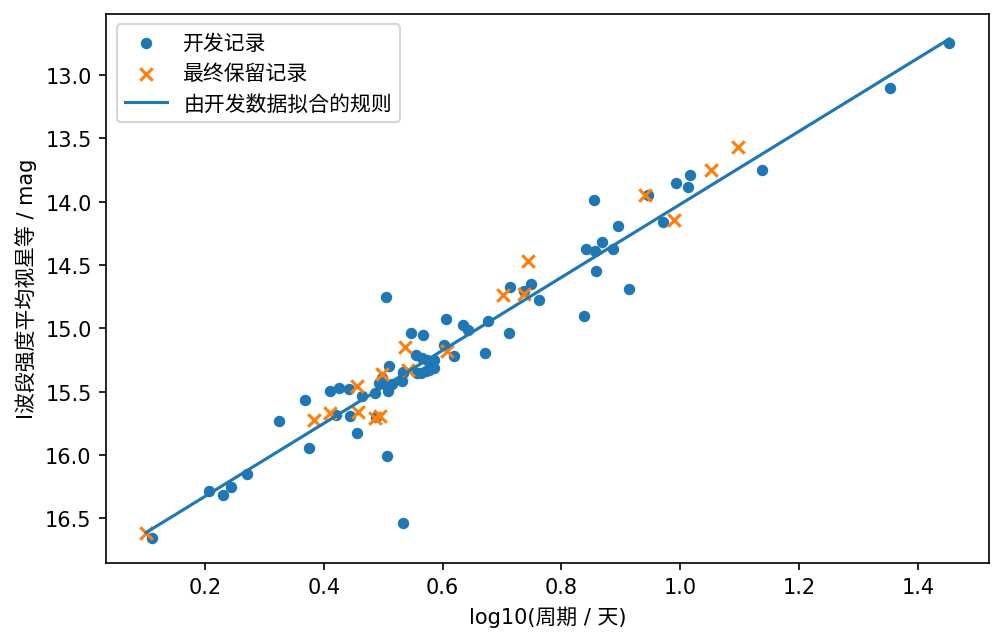

v3_project_ogle_residual.png


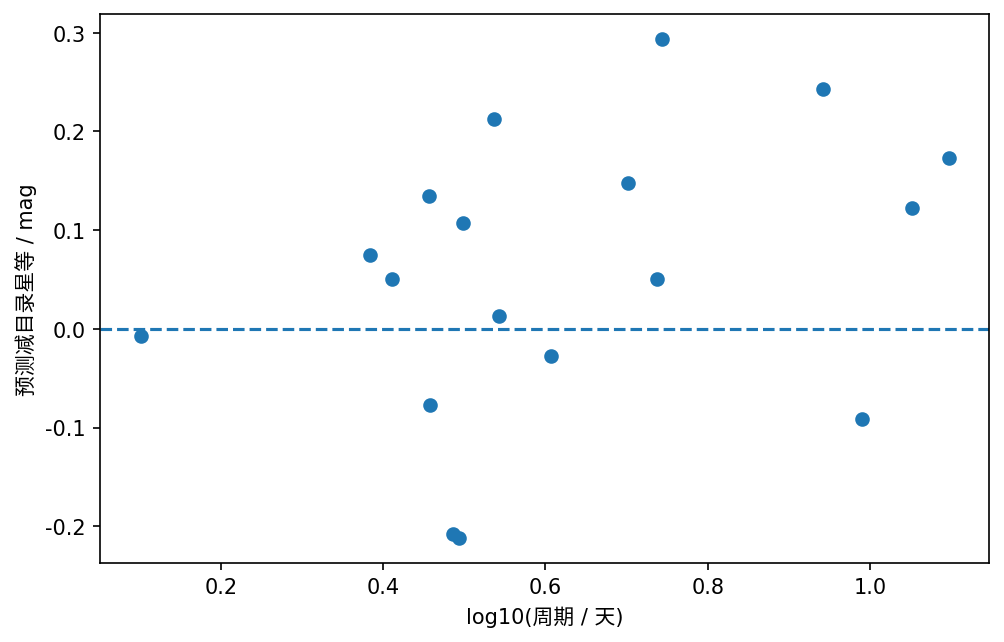

In [4]:
from IPython.display import display, Image
files = sorted((root / "figures").glob("v3_project_ogle_*.png"))
for path in files:
    print(path.name)
    display(Image(filename=str(path), width=720))
if not files:
    print("This experiment uses tables rather than a new figure.")

## 运行后的分析

解释一个与你的预判一致的结果，再解释一个需要进一步检查的现象。指出训练、验证和测试各使用哪些记录。

比较均值、原周期直线和对数周期直线，冻结后检查18条保留对象及最大残差。

**提交要求：**保存可顺序运行的Notebook、一个关键结果表、必要图形，以及150—300字的机制与限制解释。完成正文D题中与本实验相关的计算。不得仅提交最高分截图。